# 🔢 NumPy: computing on a whole column at once

**Zero Grad · Data Analysis course · Foundations**

> 📖 **The lesson (in Arabic), with diagrams and interactive widgets:** [zero-grad.com/courses/da/numpy](https://zero-grad.com/courses/da/numpy/)
>
> 🗂️ **The data:** [NileCart Sales on Kaggle](https://www.kaggle.com/datasets/a7madmostafa/nilecart-sales)

This is the solved notebook of the *NumPy* lesson.
Pandas is built on NumPy: every column of a DataFrame is a NumPy array underneath.
Learn the array once, and filtering, `sum()`, `mean()` and `groupby` in Pandas will all make sense.

| # | Part | The idea |
|---|---|---|
| 1 | Why NumPy | A list is a container, an array is a column of numbers |
| 2 | Making arrays and `dtype` | One type per array, and `NaN` is a float |
| 3 | Shape and `reshape` | 24 months become a (2 × 12) table |
| 4 | Indexing and slicing | `M[row, column]`, and a slice is a view |
| 5 | Boolean masks | Filter with a condition: `r[r > 100_000]` |
| 6 | Aggregation and `axis` | Collapse rows, or collapse columns |
| 7 | Broadcasting | Different shapes that still work together |
| 8 | Sorting | `sort`, and `argsort` to reorder another array |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.2f}".format
np.set_printoptions(suppress=True, linewidth=110)

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/nilecart/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0].parent if on_kaggle else Path("../data/nilecart")

sales = pd.read_csv(DATA / "sales.csv", parse_dates=["order_date"])
done = sales[sales["status"] == "completed"]

r = done["revenue"].to_numpy()          # the revenue of every completed order line
cat = done["category"].to_numpy()       # and its category, in the same order
prod = done["product_name"].to_numpy()
print(len(r), "completed order lines")

1074 completed order lines


---
# 1️⃣ Why NumPy?

## 1.1 A list is not a column of numbers

The same `* 2` means two different things:

In [2]:
prices_list = [63, 30400, 57]
prices = np.array(prices_list)

print("list * 2: ", prices_list * 2)     # repeats the list
print("array * 2:", prices * 2)          # doubles every number

list * 2:  [63, 30400, 57, 63, 30400, 57]
array * 2: [  126 60800   114]


In [3]:
try:
    prices_list * 1.14
except TypeError as e:
    print("list * 1.14 ->", e)
print("array * 1.14 ->", prices * 1.14)

list * 1.14 -> can't multiply sequence by non-int of type 'float'
array * 1.14 -> [   71.82 34656.      64.98]


A list is a **container**: it holds anything, and `*` repeats it.
An array is a **column of numbers**: arithmetic happens to every element, with no loop.

## 1.2 It's fast

A loop over a list, against one line on an array, for a million numbers:

In [4]:
n = 1_000_000
big_list = list(range(n))
big_arr = np.arange(n)

def best(f, k=5):                          # the fastest of k runs, in seconds
    times = []
    for _ in range(k):
        t = time.perf_counter(); f(); times.append(time.perf_counter() - t)
    return min(times)

t_list = best(lambda: [v * 1.14 for v in big_list])
t_arr = best(lambda: big_arr * 1.14)

print(f"list loop: {t_list * 1000:6.1f} ms")
print(f"array:     {t_arr * 1000:6.1f} ms   ->  about {t_list / t_arr:.0f}x faster")

list loop:   57.0 ms
array:        1.9 ms   ->  about 29x faster


The exact numbers depend on the machine; the gap is always large.
An array keeps its numbers side by side in memory, all of the same type,
so the loop runs in compiled C code instead of in Python.

---
# 2️⃣ Making arrays, and `dtype`

## 2.1 From a column, from a list, from a pattern

In [5]:
a = np.array([5, 9, 10, 5])           # from a list
q = sales["quantity"].to_numpy()      # from a DataFrame column (the usual way in this course)

print(np.arange(1, 13))               # 1 .. 12: month numbers
print(np.linspace(0, 1, 5))           # 5 evenly spaced numbers from 0 to 1
print(np.zeros(4), np.ones(4))        # placeholders
print(np.full(4, 0.14))               # the same value 4 times

[ 1  2  3  4  5  6  7  8  9 10 11 12]
[0.   0.25 0.5  0.75 1.  ]
[0. 0. 0. 0.] [1. 1. 1. 1.]
[0.14 0.14 0.14 0.14]


Random numbers, with a **seed** so you get the same ones every time you run the notebook
(NileCart itself was generated with seed 42):

In [6]:
rng = np.random.default_rng(42)
print(rng.integers(1, 11, size=8))          # 8 order quantities between 1 and 10
print(rng.normal(1000, 50, size=4).round(1))  # 4 prices around 1,000

[1 8 7 5 5 9 1 7]
[ 902.4  934.9 1006.4  984.2]


## 2.2 One array, one type

Every array has a `dtype`, and all its elements share it.

In [7]:
for name, arr in [("order_id", sales["order_id"].to_numpy()), ("revenue", r),
                  ("revenue > 100k", r > 100_000), ("category", cat)]:
    print(f"{name:15} dtype={str(arr.dtype):8} first={arr[0]!r}")

order_id        dtype=int64    first=np.int64(10002)
revenue         dtype=float64  first=np.float64(259920.0)
revenue > 100k  dtype=bool     first=np.True_
category        dtype=object   first='Electronics'


| `dtype` | What it holds | NileCart |
|---|---|---|
| `int64` | whole numbers | `order_id`, `unit_cost` |
| `float64` | numbers with a decimal point (and `NaN`) | `revenue`, `discount` |
| `bool` | `True` / `False` | the answer to a condition |
| `object` | anything, as Python objects (slow) | text columns |

Mix types and NumPy picks one type that fits them all:

In [8]:
print(np.array([1, 2, 3]).dtype)
print(np.array([1, 2, 3.5]).dtype)      # one float turns everything into float
print(np.array([1, "2", 3]).dtype)      # one string turns everything into text

int64
float64
<U21


## 2.3 Why is `quantity` a float? `NaN` is a float

A quantity is a whole number, but in `sales.csv` it reads `5.0`, not `5`.
The reason is in the raw `orders.csv`: some quantities are missing.

In [9]:
orders = pd.read_csv(DATA / "orders.csv")
oq = orders["quantity"].to_numpy()
print("dtype:", oq.dtype, "  missing:", np.isnan(oq).sum(), "of", len(oq))
print(oq[np.isnan(oq)][:5])

dtype: float64   missing: 30 of 1501
[nan nan nan nan nan]


A missing value is `np.nan` ("not a number"), and `np.nan` **is a float**.
An `int64` array has no way to hold it, so the whole column becomes `float64`.

`NaN` also spreads: any calculation that touches it gives `NaN`.

In [10]:
print("sum:       ", oq.sum())          # nan
print("nansum:    ", np.nansum(oq))      # skips the missing values
print("nanmean:   ", round(np.nanmean(oq), 2))
print("nan == nan:", np.nan == np.nan)   # so use np.isnan, never == np.nan

sum:        nan
nansum:     6504.0
nanmean:    4.42
nan == nan: False


## 2.4 Converting: `astype`

In [11]:
print(q[:5], q.dtype)
print(q.astype(int)[:5], q.astype(int).dtype)    # sales.csv has no NaN left, so this works

with np.errstate(invalid="ignore"):        # NumPy only warns, so hide the warning to see what comes out
    oq_int = oq.astype(int)
print(oq_int[np.isnan(oq)][:3], "<- what a NaN became")

[ 5.  9. 10.  5.  4.] float64
[ 5  9 10  5  4] int64
[-9223372036854775808 -9223372036854775808 -9223372036854775808] <- what a NaN became


`astype(int)` on a `NaN` doesn't stop you: it silently writes a meaningless number.
Deal with the missing values first (the cleaning lesson), then convert.

---
# 3️⃣ Shape and `reshape`

## 3.1 24 months become a table

Revenue per month, from January 2024 to December 2025: a vector of 24 numbers.

In [12]:
monthly = done.groupby(done["order_date"].dt.to_period("M"))["revenue"].sum()
m = monthly.to_numpy()
print(m.shape)
print((m / 1000).round())

(24,)
[ 547.  427.  545.  341.  631.  481.  789.  517. 1119.  982. 1285. 2075.  821.  621.  806.  381.  586.  610.
  434.  620.  662.  743. 1763. 1625.]


24 numbers in a row are hard to compare. `reshape(2, 12)` lays the same 24 numbers out as
**2 rows (years) × 12 columns (months)**, filling row by row:

In [13]:
M = m.reshape(2, 12)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
pd.DataFrame((M / 1000).round().astype(int), index=[2024, 2025], columns=MONTHS)     # thousands of EGP

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2024,547,427,545,341,631,481,789,517,1119,982,1285,2075
2025,821,621,806,381,586,610,434,620,662,743,1763,1625


Same data, new shape. Now each column is the same month in both years.

The sizes must agree: 2 × 12 = 24. `-1` means "work it out":

In [14]:
print(m.reshape(2, -1).shape)    # (2, 12)
print(m.reshape(-1, 3).shape)    # (8, 3): 8 quarters x 3 months
print(M.ravel().shape)           # back to one row of 24

try:
    m.reshape(5, 5)
except ValueError as e:
    print("reshape(5, 5) ->", e)

(2, 12)
(8, 3)
(24,)
reshape(5, 5) -> cannot reshape array of size 24 into shape (5,5)


---
# 4️⃣ Indexing and slicing

## 4.1 One dimension

Positions start at 0, and negative positions count from the end.

In [15]:
print("first:", r[0], "  last:", r[-1])
print("first 5:", r[:5])
print("every 200th:", r[::200])

first: 259920.0   last: 7220.0
first 5: [259920.     570.    4560.   31350.    1624.5]
every 200th: [259920.   3940.  23520.  22050.   1712.   1200.]


## 4.2 Two dimensions: `M[row, column]`

In [16]:
print("Nov 2025:       ", M[1, 10])        # row 1 = 2025, column 10 = November
print("2024, all year: ", M[0].round())    # a whole row
print("December, both: ", M[:, 11])        # a whole column
print("Q4 2024:        ", M[0, 9:])        # Oct, Nov, Dec of 2024

Nov 2025:        1762577.0
2024, all year:  [ 546824.  426922.  545402.  341292.  631148.  481011.  788783.  516810. 1118751.  982268. 1285090. 2075220.]
December, both:  [2075219.85 1624704.65]
Q4 2024:         [ 982267.95 1285090.4  2075219.85]


## 4.3 A slice is a view ⚠️

A slice doesn't copy the numbers: it's a **view** of the same memory.
Change the view and the original changes too.

In [17]:
a = np.array([10, 20, 30, 40, 50])
first3 = a[:3]
first3[0] = 999
print("a after changing the slice:", a)

a = np.array([10, 20, 30, 40, 50])
first3 = a[:3].copy()            # an independent copy
first3[0] = 999
print("a after changing a copy:   ", a)

a after changing the slice: [999  20  30  40  50]
a after changing a copy:    [10 20 30 40 50]


Views keep NumPy fast on big data. When you want to change a piece without touching the original, call `.copy()`.
(Pandas 2 had the same issue, behind its `SettingWithCopyWarning`. Pandas 3 avoids it: every selection behaves like a copy.)

---
# 5️⃣ Boolean masks: filtering with a condition

A comparison on an array gives an array of `True` / `False`, one per element: a **mask**.

In [18]:
mask = r > 100_000
print(r[:8])
print(mask[:8])

[259920.     570.    4560.   31350.    1624.5   3600.   22000.   66150. ]
[ True False False False False False False False]


Put the mask inside the brackets and you keep only the `True` elements.
And because `True` counts as 1, `mask.sum()` counts them:

In [19]:
big = r[mask]
print("big orders:      ", mask.sum(), "of", len(r))
print("their revenue:   ", f"{big.sum():,.0f}")
print("share of revenue:", f"{big.sum() / r.sum():.1%}")
print("share of orders: ", f"{mask.mean():.1%}")

big orders:       43 of 1074
their revenue:    6,707,770
share of revenue: 34.6%
share of orders:  4.0%


4% of the order lines bring in more than a third of the revenue. That's the long right tail from the Introduction.

## 5.1 Combining conditions: `&`, `|`, `~`

`and` / `or` / `not` don't work on arrays. Use `&` (and), `|` (or), `~` (not), with **brackets** around each condition:

In [20]:
elec = cat == "Electronics"
print("big AND Electronics:", ((r > 100_000) & elec).sum())
print("big AND not Electr.:", ((r > 100_000) & ~elec).sum())
print("Stationery OR Furniture:", ((cat == "Stationery") | (cat == "Furniture")).sum())

big AND Electronics: 43
big AND not Electr.: 0
Stationery OR Furniture: 352


In [21]:
try:
    r > 100_000 and elec
except ValueError as e:
    print("`and` ->", e)

`and` -> The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()


Every big order is Electronics: no other category has a product expensive enough.

## 5.2 `np.isin`: one of several values

In [22]:
phones_laptops = np.isin(prod, ["Laptop", "Phone"])
print(phones_laptops.sum(), "lines,", f"{r[phones_laptops].sum() / r.sum():.0%} of revenue")

116 lines, 53% of revenue


## 5.3 `np.where`: if / else on a whole column

In [23]:
size = np.where(r >= 10_000, "big", "small")
print(size[:8])
print(pd.Series(size).value_counts())

['big' 'small' 'small' 'big' 'small' 'small' 'big' 'big']
small    734
big      340
Name: count, dtype: int64


## 5.4 Changing values with a mask

In [24]:
capped = r.copy()
capped[capped > 100_000] = 100_000          # cap the extreme orders (for a chart, say)
print("max before:", r.max(), "  after:", capped.max())

max before: 336000.0   after: 100000.0


---
# 6️⃣ Aggregation and `axis`

## 6.1 One number from a whole column

In [25]:
print(f"sum     {r.sum():>14,.0f}")
print(f"mean    {r.mean():>14,.0f}")
print(f"median  {np.median(r):>14,.0f}")
print(f"std     {r.std():>14,.0f}")
print(f"min     {r.min():>14,.0f}")
print(f"max     {r.max():>14,.0f}")
print(f"90th %  {np.percentile(r, 90):>14,.0f}")

sum         19,412,322
mean            18,075
median           3,600
std             35,601
min                 46
max            336,000
90th %          53,960


The mean is five times the median: a few huge orders pull it up.
Which one to report is what we settled in *Descriptive statistics*.

## 6.2 `axis`: which direction to collapse

On a 2-D array, `axis` says which dimension disappears:

* `axis=0` collapses the **rows**: one result per column (per month).
* `axis=1` collapses the **columns**: one result per row (per year).
* no `axis`: everything, one number.

In [26]:
print("M.sum()       ", f"{M.sum():,.0f}", "  shape ()")
print("M.sum(axis=1) ", M.sum(axis=1).round(), "  shape", M.sum(axis=1).shape, "<- one per year")
print("M.sum(axis=0) ", (M.sum(axis=0) / 1000).round(), "  shape", M.sum(axis=0).shape, "<- one per month (k)")

M.sum()        19,412,322   shape ()
M.sum(axis=1)  [9739521. 9672801.]   shape (2,) <- one per year
M.sum(axis=0)  [1368. 1048. 1351.  723. 1218. 1091. 1223. 1136. 1781. 1725. 3048. 3700.]   shape (12,) <- one per month (k)


The two years are almost equal: 9.74M in 2024 and 9.67M in 2025.

`argmax` gives the **position** of the largest value, not the value:

In [27]:
peak = M.argmax(axis=1)
for year, p in zip([2024, 2025], peak):
    print(year, "peak month:", MONTHS[p], f"({M[year - 2024, p]:,.0f} EGP)")
print("best month over both years:", MONTHS[M.sum(axis=0).argmax()])

2024 peak month: Dec (2,075,220 EGP)
2025 peak month: Nov (1,762,577 EGP)
best month over both years: Dec


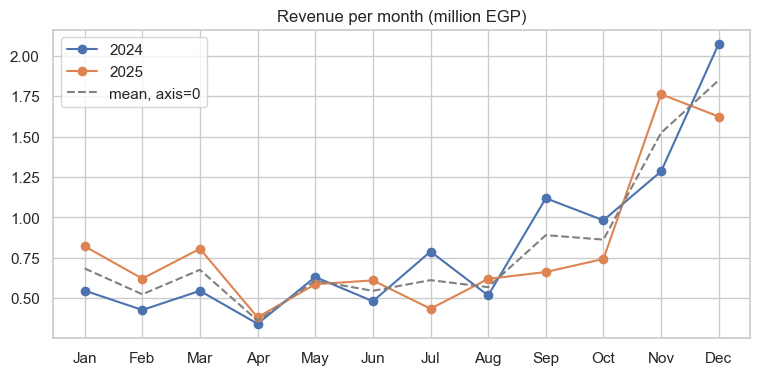

In [28]:
fig, ax = plt.subplots()
ax.plot(MONTHS, M[0] / 1e6, marker="o", label="2024")
ax.plot(MONTHS, M[1] / 1e6, marker="o", label="2025")
ax.plot(MONTHS, M.mean(axis=0) / 1e6, ls="--", color="gray", label="mean, axis=0")
ax.set(title="Revenue per month (million EGP)", ylabel="")
ax.legend()
plt.show()

---
# 7️⃣ Broadcasting

Two arrays of different shapes can still work together, when NumPy can **stretch** one to match the other.
You've already seen the simplest case: an array times a scalar, `r * 1.14`.

## 7.1 Each month's share of its year

Divide the (2 × 12) table by each year's total. The totals have shape (2,); with `keepdims=True` they stay (2 × 1),
a column, and NumPy stretches that column across the 12 months:

In [29]:
totals = M.sum(axis=1, keepdims=True)
print("M:", M.shape, "  totals:", totals.shape)

share = M / totals                      # (2, 12) / (2, 1) -> (2, 12)
pd.DataFrame(share * 100, index=[2024, 2025], columns=MONTHS).round(1)     # % of the year

M: (2, 12)   totals: (2, 1)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2024,5.60,4.40,5.60,3.50,6.50,4.90,8.10,5.30,11.50,10.10,13.20,21.30
2025,8.50,6.40,8.30,3.90,6.10,6.30,4.50,6.40,6.80,7.70,18.20,16.80


In [30]:
print(share.sum(axis=1))     # every row adds up to 1

[1. 1.]


November and December together are about 35% of the year, in both years.

## 7.2 A row against every row

Every row divided by 2024's row: a (12,) row stretched down both years.
The 2024 row becomes all ones, and the 2025 row says how each month did against the same month a year earlier:

In [31]:
base = M[0]                             # shape (12,)
print("M:", M.shape, "  base:", base.shape)
pd.DataFrame(M / base, index=[2024, 2025], columns=MONTHS).round(2)     # 1.00 = same as 2024

M: (2, 12)   base: (12,)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2024,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
2025,1.50,1.46,1.48,1.12,0.93,1.27,0.55,1.20,0.59,0.76,1.37,0.78


January to March 2025 were about 50% above 2024. July and September fell by 40–45%, and December by a fifth.

## 7.3 The rule

Line the shapes up **from the right**. Each pair of sizes must be equal, or one of them must be 1 (that one stretches).

| A | B | Result |
|---|---|---|
| (2, 12) | () scalar | (2, 12) |
| (2, 12) | (12,) | (2, 12) |
| (2, 12) | (2, 1) | (2, 12) |
| (2, 12) | (2,) | ❌ 12 vs 2 |

In [32]:
try:
    M / M.sum(axis=1)              # (2, 12) / (2,): lined up from the right, 12 vs 2
except ValueError as e:
    print(e)

operands could not be broadcast together with shapes (2,12) (2,) 


That's the most common broadcasting error, and `keepdims=True` (or `[:, None]`) is the fix.

---
# 8️⃣ Sorting

## 8.1 `np.sort`

In [33]:
print("smallest 5:", np.sort(r)[:5])
print("largest 5: ", np.sort(r)[-5:])
print("largest 5, biggest first:", np.sort(r)[::-1][:5])

smallest 5: [45.6 45.6 45.6 54.  54. ]
largest 5:  [215040. 230400. 259920. 320000. 336000.]
largest 5, biggest first: [336000. 320000. 259920. 230400. 215040.]


## 8.2 `argsort`: sort one array, reorder another

`argsort` returns the **positions** that would sort the array.
Use them on any other array of the same length, and the two stay lined up:

In [34]:
top = np.argsort(r)[::-1][:5]          # positions of the 5 largest revenues
print(top)
for i in top:
    print(f"{prod[i]:8} {r[i]:>10,.0f}")

[476 602   0 429 950]
Laptop      336,000
Laptop      320,000
Laptop      259,920
Laptop      230,400
Laptop      215,040


The months of 2025, best to worst:

In [35]:
order = np.argsort(M[1])[::-1]
print([MONTHS[i] for i in order])

['Nov', 'Dec', 'Jan', 'Mar', 'Oct', 'Sep', 'Feb', 'Aug', 'Jun', 'May', 'Jul', 'Apr']


---
# 🧰 Summary

| Idea | In one line | NumPy |
|---|---|---|
| Array, not list | arithmetic on every element | `np.array`, `df["col"].to_numpy()` |
| `dtype` | one type per array; `NaN` is a float | `arr.dtype`, `astype`, `np.isnan` |
| Missing values | `NaN` spreads | `np.nansum`, `np.nanmean` |
| Shape | same data, new layout | `reshape(2, 12)`, `reshape(-1)`, `ravel` |
| Indexing | row, column; a slice is a view | `M[1, 10]`, `M[:, 11]`, `.copy()` |
| Boolean mask | filter with a condition | `r[r > 100_000]`, `&`, `\|`, `~`, `np.isin` |
| If / else | on a whole column | `np.where(cond, a, b)` |
| Aggregation | `axis` is the dimension that disappears | `M.sum(axis=0)`, `argmax` |
| Broadcasting | sizes equal, or one of them is 1 | `M / M.sum(axis=1, keepdims=True)` |
| Sorting | values, or the positions that sort | `np.sort`, `np.argsort` |

**Next part of the course:** Pandas: reading, inspecting, selecting and filtering tables.

📚 All the lessons of the course: [zero-grad.com/courses/da](https://zero-grad.com/courses/da/)